## Лабораторная работа №1 | Вариант 3

Выполнил: 

Решения выполняются последовательно сверху вниз; случайные примеры воспроизводимы.
Для запуска нужны NumPy, Pandas, Matplotlib и ядро Python для Jupyter.
Данные описывают срез из приложенных CSV-файлов, а не текущую эпидемиологическую ситуацию.

### 1. Numpy

In [ ]:
import numpy as np

rng = np.random.default_rng(42)

1. Создайте массив D размером 4x4, заполненный числами от 1 до 16. Используйте срезы, чтобы извлечь подмассив размером 2x2, начиная с элемента в строке 1 и столбце 1.

In [ ]:
D = np.arange(1, 17).reshape(4, 4)
subarray = D[1:3, 1:3]
print("Матрица D:\n", D)
print("Подмассив 2×2:\n", subarray)

Матрица D:
 [[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]
 [13 14 15 16]]
Подмассив 2×2:
 [[ 6  7]
 [10 11]]


2. Создайте трехмерный массив a размером 4x3x2, заполненный случайными числами от 1 до 10. Найдите сумму всех элементов вдоль оси 1.

In [3]:
a = rng.integers(1, 11, size=(4, 3, 2))
axis_1_sum = a.sum(axis=1)
print("Исходный массив:\n", a)
print("Сумма вдоль оси 1 (размер 4×2):\n", axis_1_sum)

Исходный массив:
 [[[ 1  8]
  [ 7  5]
  [ 5  9]]

 [[ 1  7]
  [ 3  1]
  [ 6 10]]

 [[ 8  8]
  [ 8  8]
  [ 6  2]]

 [[ 9  5]
  [ 6  4]
  [ 2 10]]]
Сумма вдоль оси 1 (размер 4×2):
 [[13 22]
 [10 18]
 [22 18]
 [17 19]]


3. Напишите функцию, которая принимает матрицу и производит нормировку её элементов (т.е. $A'_{ij} = A_{ij} / \sum_{i} \sum_{j} A_{ij}$)

In [4]:
def normalize_matrix(matrix):
    """Разделить элементы матрицы на сумму всех её элементов."""
    matrix = np.asarray(matrix, dtype=float)
    if matrix.ndim != 2:
        raise ValueError("Ожидается двумерная матрица.")
    total = matrix.sum()
    if total == 0:
        raise ValueError("Нельзя нормировать матрицу с нулевой суммой.")
    return matrix / total

normalized_D = normalize_matrix(D)
print(normalized_D)
print("Сумма после нормировки:", normalized_D.sum())

[[0.00735294 0.01470588 0.02205882 0.02941176]
 [0.03676471 0.04411765 0.05147059 0.05882353]
 [0.06617647 0.07352941 0.08088235 0.08823529]
 [0.09558824 0.10294118 0.11029412 0.11764706]]
Сумма после нормировки: 1.0


4. Напишите функцию, которая принимает 3 трехмерных вектора $x, y, z$ и вычисляет объем пирамиды, образованной этими векторами (используйте смешанное произведение векторов)

In [ ]:
def pyramid_volume(x, y, z):
    """Объём тетраэдра с рёбрами x, y, z из общей вершины."""
    x, y, z = (np.asarray(vector, dtype=float) for vector in (x, y, z))
    if any(vector.shape != (3,) for vector in (x, y, z)):
        raise ValueError("Каждый вектор должен содержать три координаты.")
    return float(abs(np.dot(x, np.cross(y, z))) / 6)

print("Объём пирамиды:", pyramid_volume([1, 0, 0], [0, 2, 0], [0, 0, 3]))

Объём пирамиды: 1.0


5. Напишите функцию, которая принимает число N и строит матрицу NxN, с нулями внутри и единицами на границе.

In [6]:
def border_matrix(N):
    """Квадратная матрица с единичной границей и нулями внутри."""
    if not isinstance(N, (int, np.integer)) or N < 1:
        raise ValueError("N должно быть положительным целым числом.")
    matrix = np.zeros((N, N), dtype=int)
    matrix[[0, -1], :] = 1
    matrix[:, [0, -1]] = 1
    return matrix

border_matrix(5)

array([[1, 1, 1, 1, 1],
       [1, 0, 0, 0, 1],
       [1, 0, 0, 0, 1],
       [1, 0, 0, 0, 1],
       [1, 1, 1, 1, 1]])

6. Создайте матрицу шахматную доску 8х8 используя функцию `tile`

In [7]:
chessboard = np.tile([[0, 1], [1, 0]], (4, 4))
chessboard

array([[0, 1, 0, 1, 0, 1, 0, 1],
       [1, 0, 1, 0, 1, 0, 1, 0],
       [0, 1, 0, 1, 0, 1, 0, 1],
       [1, 0, 1, 0, 1, 0, 1, 0],
       [0, 1, 0, 1, 0, 1, 0, 1],
       [1, 0, 1, 0, 1, 0, 1, 0],
       [0, 1, 0, 1, 0, 1, 0, 1],
       [1, 0, 1, 0, 1, 0, 1, 0]])

7. Как найти наиболее близкое значение (к заданному скаляру) в векторе?

In [8]:
def nearest_value(vector, scalar):
    """Ближайший элемент; при равенстве расстояний — первый."""
    vector = np.asarray(vector, dtype=float)
    if vector.ndim != 1 or vector.size == 0:
        raise ValueError("Ожидается непустой одномерный вектор.")
    return vector[np.abs(vector - scalar).argmin()]

vector = np.array([1, 4, 8, 12, 17])
scalar = 10.5
print("Вектор:", vector)
print(f"Ближайший элемент к {scalar}: {nearest_value(vector, scalar)}")

Вектор: [ 1  4  8 12 17]
Ближайший элемент к 10.5: 12.0


8. Создайте случайный вектор размером 10 и отсортируйте его

In [9]:
random_vector = rng.random(10)
sorted_vector = np.sort(random_vector)
print("Исходный вектор:", random_vector)
print("Отсортированный вектор:", sorted_vector)

Исходный вектор: [0.64386512 0.82276161 0.4434142  0.22723872 0.55458479 0.06381726
 0.82763117 0.6316644  0.75808774 0.35452597]
Отсортированный вектор: [0.06381726 0.22723872 0.35452597 0.4434142  0.55458479 0.6316644
 0.64386512 0.75808774 0.82276161 0.82763117]


9. Создайте случайный вектор длиной 10 и замените максимальное значение в нем на 0

In [ ]:
vector_with_max = rng.random(10)
print("Исходный вектор:", vector_with_max)
vector_with_max[vector_with_max == vector_with_max.max()] = 0
print("После замены максимума:", vector_with_max)

Исходный вектор: [0.97069802 0.89312112 0.7783835  0.19463871 0.466721   0.04380377
 0.15428949 0.68304895 0.74476216 0.96750973]
После замены максимума: [0.         0.89312112 0.7783835  0.19463871 0.466721   0.04380377
 0.15428949 0.68304895 0.74476216 0.96750973]


10. Даны 2 массива Х и Y, постройте матрицу Коши $C$ ($C_{ij} = \frac{1}{x_i - y_j}$)

In [11]:
def cauchy_matrix(X, Y):
    """Матрица C[i, j] = 1 / (X[i] - Y[j])."""
    X, Y = np.asarray(X, dtype=float), np.asarray(Y, dtype=float)
    if X.ndim != 1 or Y.ndim != 1:
        raise ValueError("X и Y должны быть одномерными массивами.")
    differences = X[:, None] - Y[None, :]
    if np.any(differences == 0):
        raise ValueError("Элементы X и Y не должны совпадать: деление на ноль.")
    return 1 / differences

X = np.array([1, 2, 3])
Y = np.array([4, 5, 6, 7])
C = cauchy_matrix(X, Y)
C

array([[-0.33333333, -0.25      , -0.2       , -0.16666667],
       [-0.5       , -0.33333333, -0.25      , -0.2       ],
       [-1.        , -0.5       , -0.33333333, -0.25      ]])

### 2. Pandas

Представлено 2 датасета в формате CSV.

Найдите ответы на вопросы или выполните действия с предложенным датасетом

Файлы: `countries.csv`, `covid-country-data.csv`

In [12]:
from pathlib import Path
import pandas as pd
from IPython.display import display

pd.set_option("display.float_format", "{:,.2f}".format)

In [ ]:
data_dir = next(
    (folder for folder in [Path.cwd(), Path("Variant 3"), Path("1/Variant 3")]
     if (folder / "countries.csv").is_file()
     and (folder / "covid-country-data.csv").is_file()),
    None,
)
if data_dir is None:
    raise FileNotFoundError("Не найдены оба CSV-файла из папки Variant 3.")

In [14]:
data = pd.read_csv(data_dir / "countries.csv")
covid_data = pd.read_csv(data_dir / "covid-country-data.csv")

In [15]:
data.head()

,location,continent,population,life_expectancy,hospital_beds_per_thousand,gdp_per_capita
0,Afghanistan,Asia,"38,928,341.00",64.83,0.50,"1,803.99"
1,Albania,Europe,"2,877,800.00",78.57,2.89,"11,803.43"
2,Algeria,Africa,"43,851,043.00",76.88,1.90,"13,913.84"
3,Andorra,Europe,"77,265.00",83.73,NaN,NaN
4,Angola,Africa,"32,866,268.00",61.15,NaN,"5,819.49"


1. Какое общее население планеты, согласно датасету?

In [16]:
total_population = int(data["population"].sum())
print(f"Общее население по датасету: {total_population:,} человек")

Общее население по датасету: 7,757,980,095 человек


2. Выведите страну с наименьшей продолжительностью жизни

In [17]:
min_life_country = data.loc[data["life_expectancy"].idxmin(),
                            ["location", "life_expectancy"]]
min_life_country

location           Central African Republic
life_expectancy                       53.28
Name: 38, dtype: object

3. Выведите страну с наибольшим ВВП на душу населения ('gdp_per_capita')

In [18]:
max_gdp_country = data.loc[data["gdp_per_capita"].idxmax(),
                           ["location", "gdp_per_capita"]]
max_gdp_country

location              Qatar
gdp_per_capita   116,935.60
Name: 155, dtype: object

4. Заполните пропуски в 'life_expectancy' медианным значением и посчитайте среднюю продолжительность жизни

In [ ]:
median_life_expectancy = data["life_expectancy"].median()
missing_life_count = int(data["life_expectancy"].isna().sum())
data["life_expectancy"] = data["life_expectancy"].fillna(median_life_expectancy)
mean_life_expectancy = data["life_expectancy"].mean()
print(f"Медиана: {median_life_expectancy:.2f} года")
print(f"Заполнено пропусков: {missing_life_count}")
print(f"Средняя продолжительность жизни: {mean_life_expectancy:.2f} года")

Медиана: 75.09 года
Заполнено пропусков: 3
Средняя продолжительность жизни: 73.55 года


5. Выведите топ-15 стран по численности населения

In [20]:
top_15_population = data.nlargest(15, "population")[["location", "population"]]
top_15_population

,location,population
41,China,"1,439,323,774.00"
90,India,"1,380,004,385.00"
199,United States,"331,002,647.00"
91,Indonesia,"273,523,621.00"
145,Pakistan,"220,892,331.00"
27,Brazil,"212,559,409.00"
141,Nigeria,"206,139,587.00"
15,Bangladesh,"164,689,383.00"
157,Russia,"145,934,460.00"
125,Mexico,"128,932,753.00"


6. Среди стран, входящих в топ-25 по ВВП на душу населения (gdp_per_capita) выведите 5 стран с наименьшим населением

In [21]:
smallest_5_top_gdp = (
    data.nlargest(25, "gdp_per_capita")
    .nsmallest(5, "population")[["location", "gdp_per_capita", "population"]]
)
smallest_5_top_gdp

,location,gdp_per_capita,population
162,San Marino,"56,861.47","33,938.00"
21,Bermuda,"50,669.32","62,273.00"
37,Cayman Islands,"49,903.03","65,720.00"
89,Iceland,"46,482.96","341,250.00"
29,Brunei,"71,809.25","437,483.00"


7. Соедините таблицы covid-country-data и countries

In [ ]:
merged_data = data.merge(covid_data, on="location", how="left", validate="one_to_one")
print(f"После объединения: {len(merged_data)} стран")
merged_data.head()

После объединения: 210 стран


,location,continent,population,life_expectancy,hospital_beds_per_thousand,gdp_per_capita,total_cases,total_deaths,total_tests
0,Afghanistan,Asia,"38,928,341.00",64.83,0.50,"1,803.99","38,243.00","1,409.00",NaN
1,Albania,Europe,"2,877,800.00",78.57,2.89,"11,803.43","9,728.00",296.00,NaN
2,Algeria,Africa,"43,851,043.00",76.88,1.90,"13,913.84","45,158.00","1,525.00",NaN
3,Andorra,Europe,"77,265.00",83.73,NaN,NaN,"1,199.00",53.00,NaN
4,Angola,Africa,"32,866,268.00",61.15,NaN,"5,819.49","2,729.00",109.00,NaN


8. Добавьте для всех стран добавьте колонку, в которой была бы отражена смертность на 1 млн человек населения (пропуски заполните средним значением)

In [ ]:
deaths_per_million_observed = (
    merged_data["total_deaths"] / merged_data["population"] * 1_000_000
)
mean_deaths_per_million = deaths_per_million_observed.mean()
merged_data["deaths_per_million"] = deaths_per_million_observed.fillna(
    mean_deaths_per_million
)
print(f"Среднее для заполнения: {mean_deaths_per_million:.2f} на 1 млн человек")
print(f"Заполнено пропусков: {deaths_per_million_observed.isna().sum()}")
merged_data[["location", "total_deaths", "population", "deaths_per_million"]]

Среднее для заполнения: 105.76 на 1 млн человек
Заполнено пропусков: 1


,location,total_deaths,population,deaths_per_million
0,Afghanistan,"1,409.00","38,928,341.00",36.19
1,Albania,296.00,"2,877,800.00",102.86
2,Algeria,"1,525.00","43,851,043.00",34.78
3,Andorra,53.00,"77,265.00",685.95
4,Angola,109.00,"32,866,268.00",3.32
...,...,...,...,...
205,Vietnam,35.00,"97,338,583.00",0.36
206,Western Sahara,1.00,"597,330.00",1.67
207,Yemen,571.00,"29,825,968.00",19.14
208,Zambia,292.00,"18,383,956.00",15.88


In [ ]:
print(f"Исходная таблица COVID-19: {len(covid_data)} строк")

Исходная таблица COVID-19: 212 строк


In [25]:
covid_data.head()

,location,total_cases,total_deaths,total_tests
0,Afghanistan,"38,243.00","1,409.00",NaN
1,Albania,"9,728.00",296.00,NaN
2,Algeria,"45,158.00","1,525.00",NaN
3,Andorra,"1,199.00",53.00,NaN
4,Angola,"2,729.00",109.00,NaN


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Сделайте круговую диаграмму, на которой были бы отражено число заболеваний COVID-19 по континентам

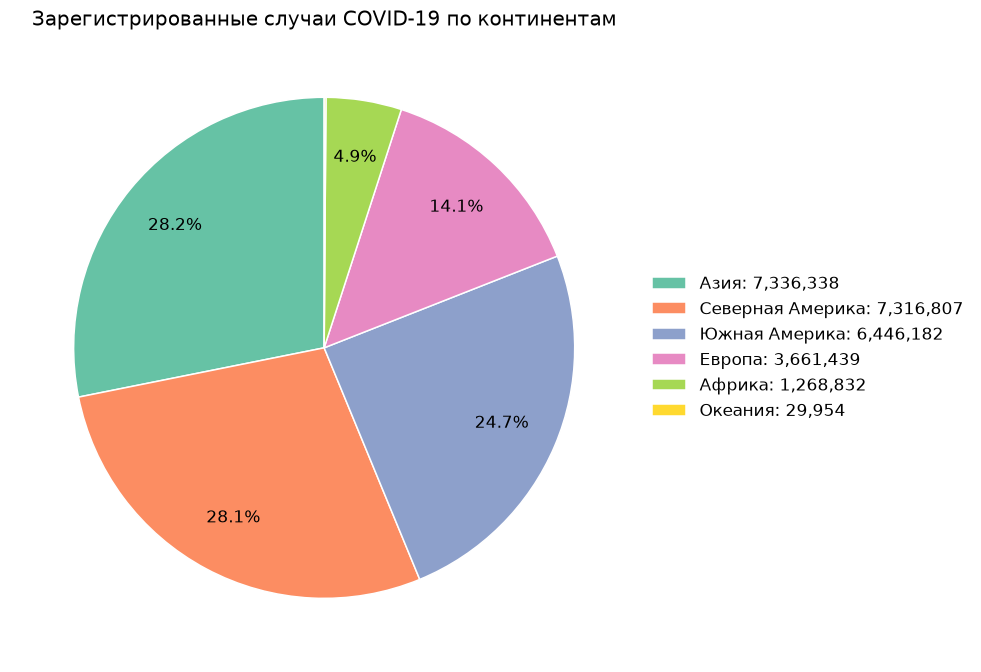

In [26]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 110,
})
continent_names = {
    "Asia": "Азия", "Europe": "Европа", "Africa": "Африка",
    "North America": "Северная Америка", "South America": "Южная Америка",
    "Oceania": "Океания",
}
cases_by_continent = merged_data.groupby("continent")["total_cases"].sum().sort_values(
    ascending=False
)
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
wedges, _, _ = ax.pie(
    cases_by_continent, autopct=lambda percent: f"{percent:.1f}%" if percent >= 1 else "", startangle=90,
    colors=plt.cm.Set2.colors, pctdistance=0.77,
    wedgeprops={"edgecolor": "white"},
)
labels = [
    f"{continent_names[name]}: {int(value):,}"
    for name, value in cases_by_continent.items()
]
ax.legend(wedges, labels, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
ax.set_title("Зарегистрированные случаи COVID-19 по континентам")
plt.show()

2. Постройте диаграмму, на которой в порядке убывания были бы отмечены число тестов на COVID-19 в России, Китае, США, Индии и Нигерии

,Количество тестов
location,
United States,"83,898,416.00"
India,"44,337,201.00"
Russia,"37,176,827.00"
Nigeria,"405,916.00"
China,NaN


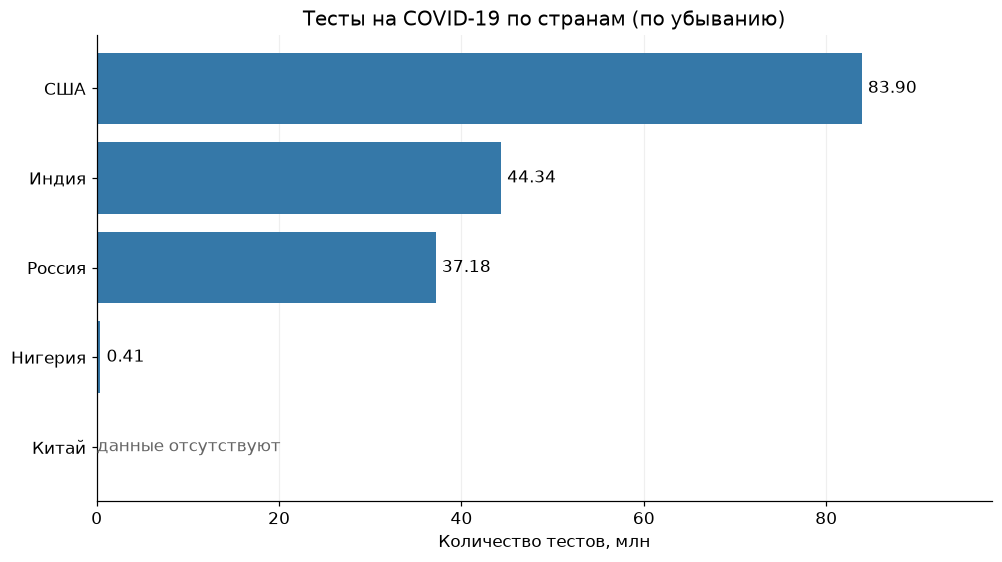

In [ ]:
country_names = {
    "Russia": "Россия", "China": "Китай", "United States": "США",
    "India": "Индия", "Nigeria": "Нигерия",
}
tests = (
    merged_data.set_index("location")["total_tests"]
    .reindex(list(country_names)).sort_values(ascending=False, na_position="last")
)
display(tests.rename("Количество тестов").to_frame())
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
positions = np.arange(len(tests))
available = tests.notna().to_numpy()
bars = ax.barh(positions[available], tests[available] / 1_000_000, color="#3578a8")
ax.bar_label(bars, fmt="%.2f", padding=4)
ax.set_yticks(positions, [country_names[name] for name in tests.index])
for position in positions[~available]:
    ax.text(0, position, "данные отсутствуют", va="center", color="#666666")
ax.set_ylim(-0.6, len(tests) - 0.4)
ax.invert_yaxis()
ax.set_xlim(0, tests.max() / 1_000_000 * 1.17)
ax.set_xlabel("Количество тестов, млн")
ax.set_title("Тесты на COVID-19 по странам (по убыванию)")
ax.xaxis.grid(alpha=0.2)
ax.set_axisbelow(True)
plt.show()

3. Визуализируйте зависимость ВВП страны и случаев заболевания COVID-19

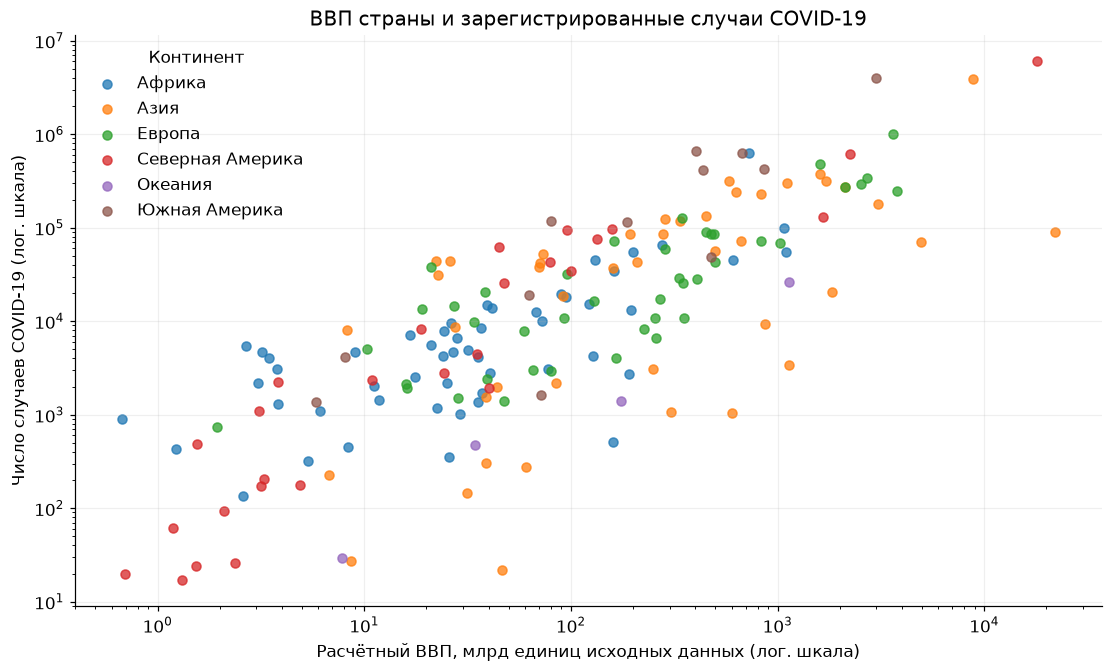

In [ ]:
gdp_cases = merged_data.dropna(subset=["gdp_per_capita", "total_cases"]).copy()
gdp_cases["estimated_gdp"] = gdp_cases["gdp_per_capita"] * gdp_cases["population"]
gdp_cases = gdp_cases[(gdp_cases["estimated_gdp"] > 0) & (gdp_cases["total_cases"] > 0)]

fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
for continent, group in gdp_cases.groupby("continent"):
    ax.scatter(group["estimated_gdp"] / 1e9, group["total_cases"],
               label=continent_names[continent], alpha=0.75, s=35)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Расчётный ВВП, млрд единиц исходных данных (лог. шкала)")
ax.set_ylabel("Число случаев COVID-19 (лог. шкала)")
ax.set_title("ВВП страны и зарегистрированные случаи COVID-19")
ax.legend(title="Континент", frameon=False)
ax.grid(alpha=0.2)
plt.show()

4. Постройте гистограмму распределения количества смертей на один миллион человек

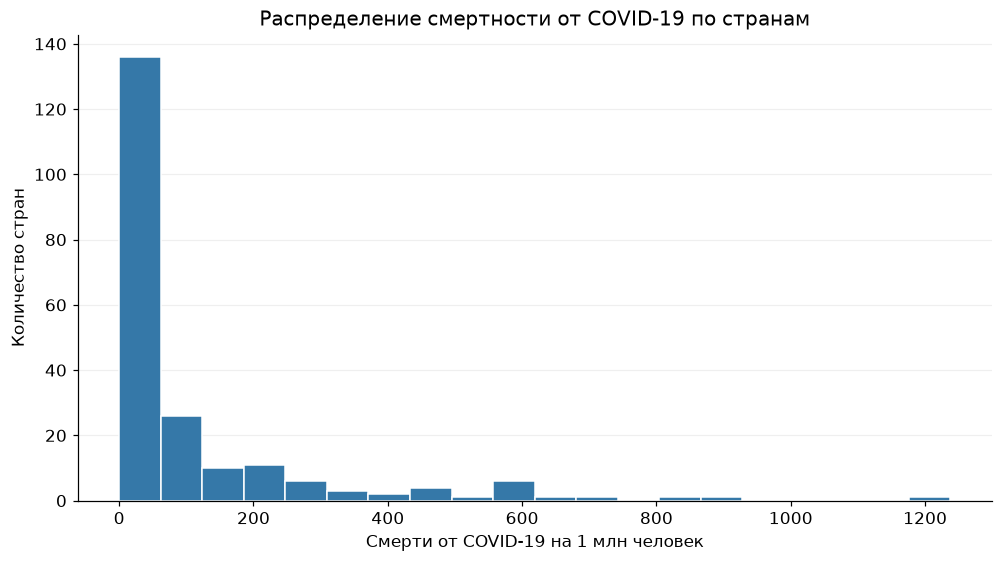

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
ax.hist(merged_data["deaths_per_million"], bins=20, color="#3578a8", edgecolor="white")
ax.set_xlabel("Смерти от COVID-19 на 1 млн человек")
ax.set_ylabel("Количество стран")
ax.set_title("Распределение смертности от COVID-19 по странам")
ax.yaxis.grid(alpha=0.2)
ax.set_axisbelow(True)
plt.show()

5. Постройте диаграмму отображающую среднюю продолжительность жизни в разных странах европы

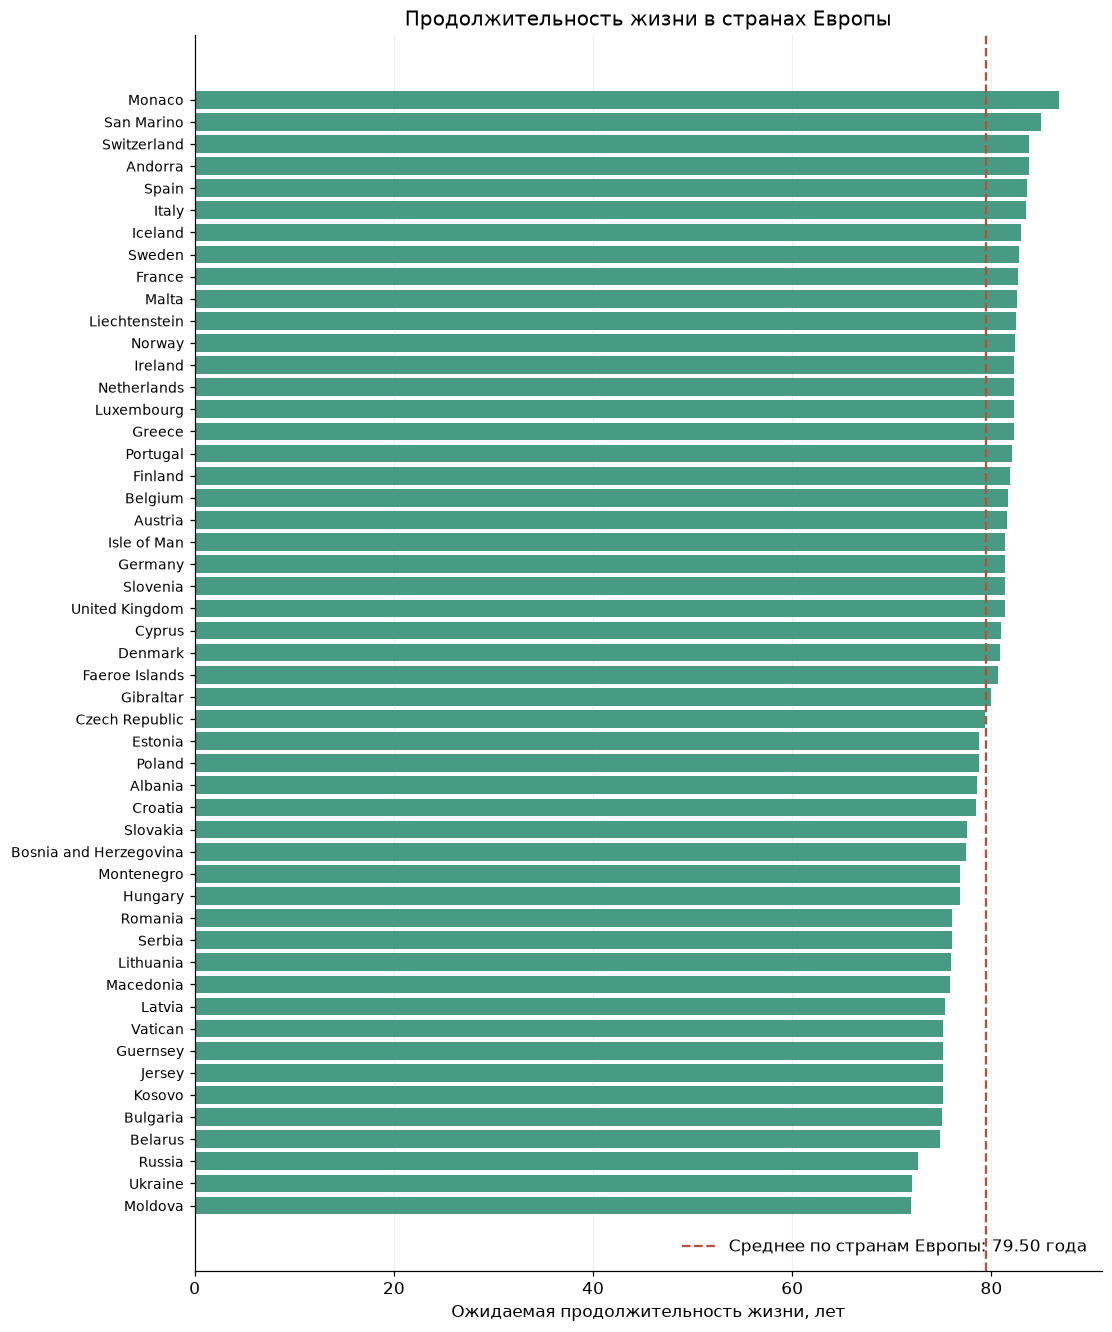

In [30]:
europe_life = merged_data.loc[
    merged_data["continent"].eq("Europe"), ["location", "life_expectancy"]
].sort_values("life_expectancy")
fig, ax = plt.subplots(figsize=(10, 12), layout="constrained")
ax.barh(europe_life["location"], europe_life["life_expectancy"], color="#479b82")
ax.axvline(europe_life["life_expectancy"].mean(), color="#b74e3e", linestyle="--",
           label=f"Среднее по странам Европы: {europe_life['life_expectancy'].mean():.2f} года")
ax.set_xlabel("Ожидаемая продолжительность жизни, лет")
ax.set_title("Продолжительность жизни в странах Европы")
ax.tick_params(axis="y", labelsize=9)
ax.legend(loc="lower right", frameon=False)
ax.xaxis.grid(alpha=0.2)
ax.set_axisbelow(True)
plt.show()

6. Сравните распределения кол-ва смертей на 1000 человек в Европе и Африке

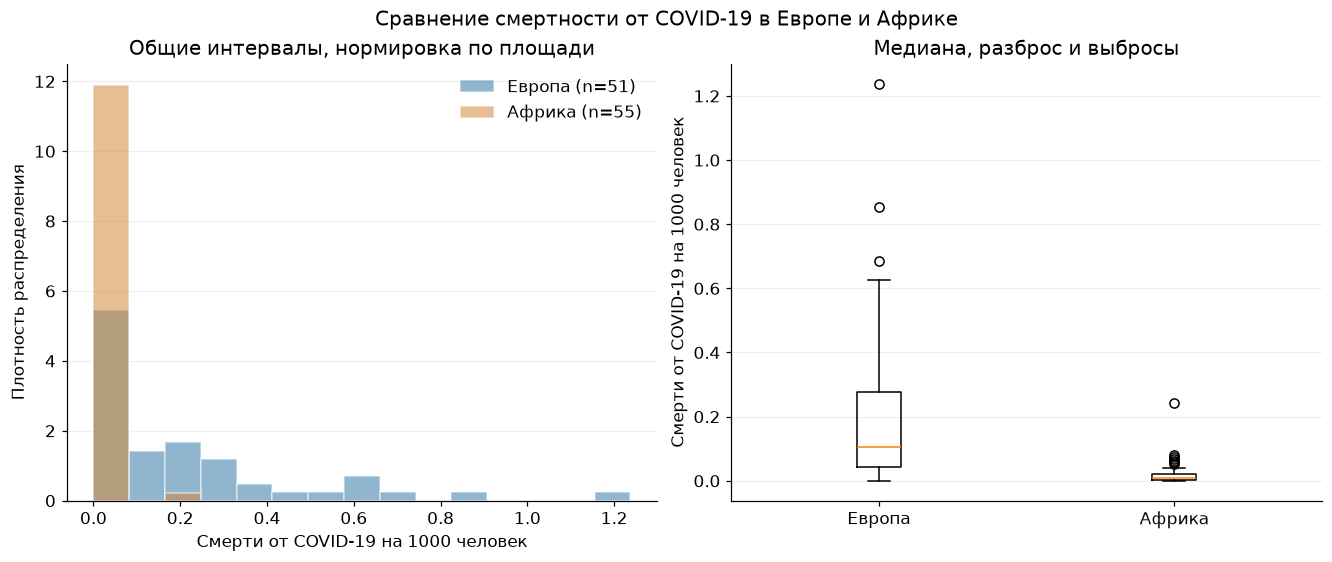

,count,mean,median,std
continent,,,,
Африка,55,0.02,0.01,0.04
Европа,51,0.21,0.11,0.25


In [ ]:
comparison = merged_data.loc[
    merged_data["continent"].isin(["Europe", "Africa"]), ["continent"]
].copy()
comparison["deaths_per_thousand"] = deaths_per_million_observed / 1000
comparison = comparison.dropna(subset=["deaths_per_thousand"])
shared_bins = np.histogram_bin_edges(comparison["deaths_per_thousand"], bins=15)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
distributions = []
for continent, color in [("Europe", "#3578a8"), ("Africa", "#d18a38")]:
    values = comparison.loc[comparison["continent"].eq(continent), "deaths_per_thousand"]
    distributions.append(values)
    axes[0].hist(values, bins=shared_bins, density=True, alpha=0.55, color=color,
                 label=f"{continent_names[continent]} (n={len(values)})", edgecolor="white")
axes[0].set_xlabel("Смерти от COVID-19 на 1000 человек")
axes[0].set_ylabel("Плотность распределения")
axes[0].set_title("Общие интервалы, нормировка по площади")
axes[0].legend(frameon=False)
axes[1].boxplot(distributions, tick_labels=["Европа", "Африка"])
axes[1].set_ylabel("Смерти от COVID-19 на 1000 человек")
axes[1].set_title("Медиана, разброс и выбросы")
for ax in axes:
    ax.yaxis.grid(alpha=0.2)
    ax.set_axisbelow(True)
fig.suptitle("Сравнение смертности от COVID-19 в Европе и Африке")
plt.show()
display(comparison.groupby("continent")["deaths_per_thousand"].agg(
    ["count", "mean", "median", "std"]
).rename(index=continent_names))